# **Data Mining Project: ACDC' Customer Segmentation (Group 30)**
This first notebook will be about Exploratory Data Analysis (EDA). Here it will be examined the coworking membership dataset in detail, focusing on uncovering meaningful patterns, identifying limitations, and generating initial hypotheses about
customer groups. It reads `acdc_dataset.csv`from `../data/raw/`, and saves the submission in `../data/processed/`.

## **Part 1. Exploratory Data Analysis**

### **1.Setup**

In [19]:
# library imports

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil

#created paths 

raw_data_path=os.path.join("..", "data", "raw", "acdc_dataset.csv")
processed_data_path=os.path.join("..", "data", "processed")

#created dataframe

df_acdcd_data= pd.read_csv(raw_data_path, index_col="member_id", sep=";")

### **2.Loading Data and First Look**

#### **2.1. Overall First Look**

In [20]:
print(f"Rows:{df_acdcd_data.shape[0]:,} | Columns:{df_acdcd_data.shape[1]:,}")
df_acdcd_data.head().T

Rows:15,465 | Columns:30


member_id,CW000001,CW000002,CW000003,CW000004,CW000005
age,38.0,38.0,43.0,38.0,45.0
gender,Female,Male,Male,F,Female
industry,Information Technology,Information Technology,Education,Legal,Information Technology
country,Portugal,Portugal,DE,portugal,United Kingdom
is_team_account,False,True,True,False,False
n_colleagues_on_account,0,2,1,0,0
plan_tier,flex,HOT_DESK,flex,flex,hot_desk
plan_days_per_week,3,2,3,3,2
membership_start,2021-08-01,2023-11-24,2021-12-03,2022-01-02,2023-10-24
membership_end,2023-03-06,1970-01-01,1970-01-01,2022-02-15,1970-01-01


A preliminary examination of the first few records reveals immediate formatting inconsistencies across categorical variables. 
Specifically, the `gender`, `country`, and `plan_tier` features exhibit non-standardised string entries (e.g., variations in casing, whitespace, and abbreviations). 

Furthermore, a relational check between temporal features indicates logical contradictions, as certain entries display a `membership_start` date that post-dates the corresponding `membership_end` date.

#### **Metadata**
- *member_id*: Unique identifier of each member

- *age*: Age of the member at the extraction date.

- *gender*: Gender of the member.

- *country*: The country where the member (or their associated company) is based.

- *industry*: The industry sector the member works in.

- *is_team_account*: Whether the membership is held by a team/company account rather than an individual.

- *n_colleagues_on_account*: Number of colleagues sharing the account.

- *plan_tier*: Current membership tier. (hot_desk < flex < dedicated_desk <full_time < private_office)

- *plan_days_per_week*: Number of days per week the member's plan entitles them to use the space.

- *membership_start*: Date the membership first began.

- *membership_end*: Date the membership first ended.

- *last_badge_swipe*: Date of the member's most recent physical entry to the space.

- *days_since_last_visit*:  Number of days since the member's last recorded visit.

- *total_visits*: Total number of visits the member made over the whole membership.

- *avg_weekly_visits*: Average number of visits per week over the membership.

- *entitled_visits_last_period*: Number of visits the member's plan entitled them to during the last period of their membership.

- *actual_visits_last_period*: Number of visits the member actually made during the last period of their membership.
- *meeting_room_hours*: Hours of meeting-room usage recorded for the member.

- *event_space_hours*: Hours of event-space usage recorded for the member.

- *guest_passes_issued*: Number of guest passes the member issued.

- *uses_meeting_rooms*: Whether the member ever used the meeting-room add-on.

- *uses_event_space*: Whether the member ever used the event-space add-on.

- *uses_guest_passes*: Whether the member ever used the guest-pass add-on.

- *uses_print*: Whether the member used the print add-on.

- *uses_mail_handling*: Whether the member used the mail-handling add-on.

- *uses_phone_booths*: Whether the member used the phone-booth add-on.

- *uses_day_passes*: Whether the member used the day-pass add-on.

- *uses_storage*: Whether the member used the storage add-on.

- *uses_bike_locker*: Whether the member used the bike-locker add-on.

- *n_renewals*: Number of times the membership was renewed.

- *lifetime_value*: Total revenue attributed to the member over the whole membership.

In [21]:
df_acdcd_data.info()
print()
df_acdcd_data.dtypes

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths                 bool
uses_day_passes          

The dataset contains incomplete entries across several columns, most notably `age`, `gender`, `country`, `plan_tier`, `meeting_room_hours`, and `guest_passes_issued`. Additionally, memory usage, feature data types, and total row counts are established to guide subsequent data type casting and handling of missing values.

In [22]:
df_acdcd_data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


Descriptive statistics highlight notable distributional anomalies across numerical features. The `age` feature displays an implausible maximum value of 149 years, indicating possible data entry errors. 

Additionally, several numerical variables, including `n_colleagues_on_account`, `days_since_last_visit`, `total_visits`, `meeting_room_hours`, `event_space_hours`, `guest_passes_issued` and `n_renewals`, exhibit impossible negative minimum values. 

Lastly, a comparison between the 75th percentile and maximum values for `n_colleagues_on_account`, `avg_weekly_visits`, `meeting_room_hours`, `event_space_hours`, and `guest_passes_issued` reveals a severe right-skewed distribution, suggesting the presence of extreme upper values that warrant dedicated outlier analysis.

#### **2.2. Grouping the Variables**

To better understand, visualise and organize our data we chose to group the variables by themes:

In [23]:
# special structural roles
index_col = "member_id"

#important feature groups
var_groups = {
    "Identifiers & Demographics": [
        "age",
        "gender",
        "industry",
        "country"
    ],
    "Account & Contract Details": [
        "is_team_account",
        "n_colleagues_on_account",
        "plan_tier",
        "plan_days_per_week",
        "membership_start",
        "membership_end",
        "n_renewals"
    ],
    "Value-based (Financial)": [
        "lifetime_value"
    ],
    "Behavioral (Visits & Recency)": [
        "last_badge_swipe",
        "days_since_last_visit",
        "total_visits",
        "avg_weekly_visits",
        "entitled_visits_last_period",
        "actual_visits_last_period"
    ],
    "Behavioral (Usage & Services)": [
        "meeting_room_hours",
        "event_space_hours",
        "guest_passes_issued",
        "uses_meeting_rooms",
        "uses_event_space",
        "uses_guest_passes",
        "uses_print",
        "uses_mail_handling",
        "uses_phone_booths",
        "uses_day_passes",
        "uses_storage",
        "uses_bike_locker"
    ]
}

# groups table
df_var_summary = pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in var_groups.items()],
    columns=["Group", "# vars", "Variables"]
)

# numerical features
numeric_features = [
    "age",
    "n_colleagues_on_account",
    "plan_days_per_week",
    "n_renewals",
    "lifetime_value",
    "days_since_last_visit",
    "total_visits",
    "avg_weekly_visits",
    "entitled_visits_last_period",
    "actual_visits_last_period",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
]

# categorical features 
# plan_tier is ordinal: hot_desk < flex < dedicated_desk < full_time < private_office
categorical_features = [
    "gender",
    "industry",
    "country",
    "plan_tier",
]

# binary features (True/False)
binary_features = [
    "is_team_account",
    "uses_meeting_rooms",
    "uses_event_space",
    "uses_guest_passes",
    "uses_print",
    "uses_mail_handling",
    "uses_phone_booths",
    "uses_day_passes",
    "uses_storage",
    "uses_bike_locker",
]

# date features
date_features = [
    "membership_start",
    "membership_end",
    "last_badge_swipe",
]

# candidate features for the models
model_features = numeric_features + categorical_features + binary_features

# every column must belong to exactly one group
all_grouped = set(model_features + date_features)
print("Columns not assigned to any group:", set(df_acdcd_data.columns) - all_grouped)
print("Total candidate features:", len(model_features))

Columns not assigned to any group: set()
Total candidate features: 27


###  **3. Data Quality Assessment**

  Before changing anything, we first diagnose the problems.

#### **3.1. Duplicates**

> ⚠️ **TO DO (Duplicates):** `drop_duplicates()` removed 167 distinct members. Re-run with `reset_index().drop_duplicates().set_index("member_id")` and update all counts that depend on the number of rows (15,283, 4,319, percentages).

In [24]:
# 1. exact duplicates, including member_id
n_exact = df_acdcd_data.reset_index().duplicated().sum()
print("Exact duplicates (incl. member_id):", n_exact)

# 2. same member_id: are the rows identical or do they conflict?
dup_ids = df_acdcd_data.index[df_acdcd_data.index.duplicated(keep=False)]
print("Rows sharing a member_id:", len(dup_ids))
df_acdcd_data.loc[dup_ids].sort_index().head(10)

# 3. identical values but different member_id
twins = df_acdcd_data[df_acdcd_data.duplicated(keep=False) & ~df_acdcd_data.index.isin(dup_ids)]
print("Rows with identical values but different member_id:", len(twins))
twins.sort_values(list(df_acdcd_data.columns)).head(10)

Exact duplicates (incl. member_id): 15
Rows sharing a member_id: 30
Rows with identical values but different member_id: 330


,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW015022,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,...,False,False,0,True,True,False,True,False,0,20683.24
CW009914,20.0,Female,Finance,Portugal,False,0,dedicated_desk,5,2021-10-22,2023-09-21,...,False,False,1,False,False,False,True,False,1,10077.14
CW015057,20.0,Female,Finance,Portugal,False,0,dedicated_desk,5,2021-10-22,2023-09-21,...,False,False,1,False,False,False,True,False,1,10077.14
CW009074,20.0,Female,Marketing & PR,Portugal,False,0,private_office,7,2021-12-05,2023-12-11,...,False,False,0,True,True,True,False,False,1,17062.12
CW015072,20.0,Female,Marketing & PR,Portugal,False,0,private_office,7,2021-12-05,2023-12-11,...,False,False,0,True,True,True,False,False,1,17062.12
CW011630,20.0,Male,Information Technology,Portugal,True,2,flex,3,2021-04-09,2021-12-09,...,False,False,1,False,False,False,False,False,1,1507.84
CW015137,20.0,Male,Information Technology,Portugal,True,2,flex,3,2021-04-09,2021-12-09,...,False,False,1,False,False,False,False,False,1,1507.84
CW015176,21.0,Female,Finance,Portugal,False,0,flex,3,2021-11-02,2021-12-04,...,False,False,1,False,False,False,False,False,0,197.5
CW002280,21.0,Female,Finance,Portugal,False,0,flex,3,2021-11-02,2021-12-04,...,False,False,1,False,False,False,False,False,0,197.5


In [25]:
import os

print("File path:", os.path.abspath(raw_data_path))

df_raw = pd.read_csv(raw_data_path, index_col="member_id", sep=";")
print("Shape df_raw        :", df_raw.shape)
print("Unique member_id's  :", df_raw.index.nunique())
print("Shape df_acdcd_data :", df_acdcd_data.shape)
print("Same object?        :", df_raw is df_acdcd_data)

File path: /Users/filipeaugusto/Desktop/Ambiente de Trabalho/Faculdade/MASTERS/Data Mining/DataMining2627/data/raw/acdc_dataset.csv
Shape df_raw        : (15465, 30)
Unique member_id's  : 15450
Shape df_acdcd_data : (15465, 30)
Same object?        : False


In [26]:
# absolute duplicated rows (100% equal)
n_dup_rows = df_acdcd_data.duplicated().sum()

# duplicated by member_id
n_dup_ids = df_acdcd_data.index.duplicated().sum()
n_members = df_acdcd_data.index.nunique()
print(f"Absolute duplicated rows : {n_dup_rows}")
print(f"Duplicated member_id's   : {n_dup_ids}")
print(f"Unique member_id's       : {n_members}")
print(f"Total rows in dataset    : {len(df_acdcd_data)}")



# absolute duplicated rows remotion
if n_dup_rows > 0:
    df_acdcd_data = df_acdcd_data.drop_duplicates()
    print(f"\n[SUCCESS] {n_dup_rows} identical rows removed.")

# duplicated by member_id inspection
if n_dup_ids > 0:
    print(f"\n[WARNING] There are {n_dup_ids} duplicate 'member_id' index entries!")
else:
    print("\n[OK] All 'member_id' index values are unique.")

Absolute duplicated rows : 182
Duplicated member_id's   : 15
Unique member_id's       : 15450
Total rows in dataset    : 15465

[SUCCESS] 182 identical rows removed.

[WARNING] There are 15 duplicate 'member_id' index entries!


The dataset contains neither absolute duplicate rows nor duplicated `member_id` values. This confirms that each record is unique and that every `member_id` identifies a single member.

#### **3.2. Missing Values**

                     Missing_Count  Missing_Pct (%)  Unique_Values
meeting_room_hours            1281             8.38           1772
guest_passes_issued           1256             8.22            205
lifetime_value                1028             6.73          11860
age                            549             3.59             84
gender                         524             3.43             12
country                        424             2.77             33
plan_tier                      103             0.67             19


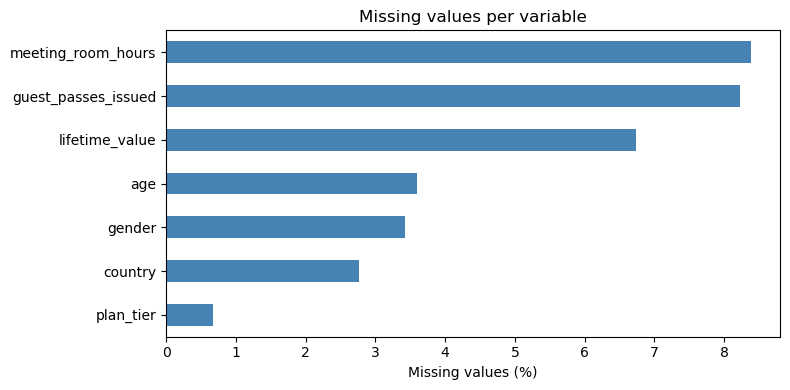

In [27]:
# missing values table resume
missing_summary = pd.DataFrame({
    'Missing_Count': df_acdcd_data.isnull().sum(),
    'Missing_Pct (%)': (df_acdcd_data.isnull().sum() / len(df_acdcd_data) * 100).round(2),
    'Unique_Values': df_acdcd_data.nunique()
})

# sort by descending number of missing values.
missing_df = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Pct (%)', ascending=False)

#did we find missing values?
if len(missing_df) > 0:
    print(missing_df)
else:
    print("No missing values!")


# graph
missing_df['Missing_Pct (%)'].sort_values().plot(
    kind='barh', figsize=(8, 4), color='steelblue')
plt.xlabel('Missing values (%)')
plt.title('Missing values per variable')
plt.tight_layout()
plt.show()    

We evaluated missingness across both columns and individual rows to determine whether any records contained incomplete customer information.

At the column level, seven variables contain missing values, all with relatively low percentages (below 9%). The feature with the highest proportion of missing data is `meeting_room_hours`, with 1,281 missing values (8.38%), followed by `guest_passes_issued` (8.22%), `lifetime_value` (6.73%), `age` (3.59%), `gender` (3.43%), `country` (2.77%) and `plan_tier` (0.67%).

As no variable exhibits a particularly high proportion of missing values, removing entire columns is not considered necessary. Instead, the treatment will be determined on a feature-by-feature basis. 

It is also worth noting that missing values in categorical variables may currently be underestimated, as inconsistent category labels (e.g. `F` and `Female`) have not yet been addressed.


For the usage-related variables (`meeting_room_hours` and `guest_passes_issued`), it will be necessary to assess whether missing values represent non-usage. The treatment of `lifetime_value` requires particular attention, given its importance for value-based customer segmentation (Financial segment).

In [31]:
# evaluation of non-usage values (meeting_room_hours)
print(df_acdcd_data.loc[df_acdcd_data['meeting_room_hours'].isna(), 'uses_meeting_rooms'].value_counts())
print()
# and the opposite: when uses_meeting_rooms is False, what are the hours?
print(df_acdcd_data.loc[~df_acdcd_data['uses_meeting_rooms'], 'meeting_room_hours'].describe())

print("\n" + "-" * 40 + "\n")

# evaluation of non-usage values (guest_passes_issued)
print(df_acdcd_data.loc[df_acdcd_data['guest_passes_issued'].isna(), 'uses_guest_passes'].value_counts())
print()
print(df_acdcd_data.loc[~df_acdcd_data['uses_guest_passes'], 'guest_passes_issued'].describe())

uses_meeting_rooms
False    893
True     388
Name: count, dtype: int64

count    9178.000000
mean        0.054598
std         0.822178
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        20.000000
Name: meeting_room_hours, dtype: float64

----------------------------------------

uses_guest_passes
False    1055
True      201
Name: count, dtype: int64

count    11445.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: guest_passes_issued, dtype: float64


Missing values in `meeting_room_hours` and `guest_passes_issued` were cross-referenced with their respective usage flags. Of the missing values, 893 out of 1,281 and 1,055 out of 1,256 are False (which correspond to not usage of the room), respectively. These missing values are not the best approach to this situation so it must be replaced with zero. The remaining 388 and 201 values correspond to users and will require imputation.

Furthermore, some members with `uses_meeting_rooms = False` have recorded usage hours above zero (up to 20 hours). So it's a situation to be analysed.

In [ ]:
# members who say they never used meeting rooms, but have hours > 0
mask_incons = (~df_acdcd_data['uses_meeting_rooms']) & (df_acdcd_data['meeting_room_hours'] > 0)
incons_rows = df_acdcd_data.loc[mask_incons]

print("Number of rows:", len(incons_rows))
print(incons_rows['meeting_room_hours'].describe())
#which columns with no usage of room have meeting_room hours?
print(incons_rows['meeting_room_hours'].value_counts().sort_index())
print()
# columns that help to understand them
cols_view = ['meeting_room_hours', 'uses_meeting_rooms', 'plan_tier',
             'is_team_account', 'total_visits', 'membership_start',
             'membership_end', 'lifetime_value']
incons_rows[cols_view].sort_values('meeting_room_hours', ascending=False).head(20)

Number of rows: 55
count    55.000000
mean      9.110909
std       5.553300
min       1.000000
25%       4.050000
50%       9.000000
75%      13.700000
max      20.000000
Name: meeting_room_hours, dtype: float64
meeting_room_hours
1.0     1
1.4     2
1.5     1
1.9     1
2.2     1
2.3     1
3.1     2
3.3     1
3.4     1
3.8     1
3.9     1
4.0     1
4.1     1
4.7     1
4.8     1
5.5     3
5.6     1
6.2     1
6.7     1
7.3     1
7.9     1
8.4     2
9.0     1
9.1     2
9.4     1
9.6     1
10.0    1
10.6    1
11.2    1
11.5    1
11.6    1
11.7    1
12.2    1
12.3    1
13.5    1
13.9    1
14.1    1
14.4    1
15.2    1
15.4    1
15.9    1
16.1    2
17.2    1
17.6    1
18.5    1
19.2    1
19.8    1
20.0    1
Name: count, dtype: int64



,meeting_room_hours,uses_meeting_rooms,plan_tier,is_team_account,total_visits,membership_start,membership_end,lifetime_value
member_id,,,,,,,,
CW010367,20.0,False,flex,False,7,2021-10-16,2021-12-18,372.61
CW010133,19.8,False,flex,False,11,29/10/2022,1970-01-01,2883.6
CW012266,19.2,False,hot_desk,False,101,2022-08-18,2023-08-25,1589.54
CW003763,18.5,False,FLEX,False,184,2021-07-08,2023-05-14,4387.19
CW011007,17.6,False,hot_desk,True,3,2023-06-08,2023-07-26,0
CW011932,17.2,False,full_time,False,130,2021-04-27,2021-12-27,2393.01
CW003567,16.1,False,hot_desk,False,72,2022-11-07,2023-08-17,1351.28
CW009873,16.1,False,private_office,False,779,2021-01-01,1970-01-01,25470.55
CW014035,15.9,False,flex,False,5,2023-12-20,1970-01-01,94.17


Here we can understand that 55 members flagged as non-users of meeting rooms have recorded usage hours above zero (1 to 20 hours). 

These hours are varied and not concentrated in any plan tier or account type, which suggests genuine usage records rather than a default value or a systematic error. 

The most likely explanation is that the `uses_meeting_rooms` flag is outdated or incorrectly filled for these members, rather than the hours being wrong. This inconsistency will be addressed in the data consistency checks.

Now, it's also interesting to determine whether missing values are concentrated in specific incomplete customer profiles, so we also analysed missingness at the row level (`member_id`).

In [33]:
# total number of columns (member_id is the index, so it is not counted)
total_cols = df_acdcd_data.shape[1]

# missing values per row (absolute value and percentage)
n_missing = df_acdcd_data.isna().sum(axis=1)

row_missing = pd.DataFrame({
    'n_missing': n_missing,
    'pct_missing': (n_missing / total_cols * 100).round(2)
}, index=df_acdcd_data.index)

# how many rows have 0, 1, 2, ... missing values?
print(row_missing['n_missing'].value_counts().sort_index())

# rows with more than 50% of the variables missing
high_missing_threshold = total_cols / 2
high_missing_rows = (
    row_missing
    .query("n_missing > @high_missing_threshold")
    .sort_values("n_missing", ascending=False)
)

print(f"\nTotal number of columns: {total_cols}")
print(f"There are {high_missing_rows.shape[0]} members with more than 50% missing values.")

high_missing_rows

n_missing
0    10964
1     3549
2      694
3       76
Name: count, dtype: int64

Total number of columns: 30
There are 0 members with more than 50% missing values.


,n_missing,pct_missing
member_id,,


The analysis shows that approximately 28% of the dataset's records (4,319 out of 15,283) contain at least one missing value. 

Among these records, the majority have missing values in only one feature. This indicates that missing data is relatively limited at the individual record level, with no records exhibiting a substantial proportion of missing values. 

Therefore, the elimination of records solely due to an excessive number of missing values does not appear necessary at this stage.

However, is important to note that this analysis only captures explicit missing values (`NaN`). Disguised possible missing values, for instance`membership_end = 1970-01-01` and entries that become `NaN` after type conversion (`lifetime_value`) are not yet reflected, so this check will be repeated after data cleaning.


REFORMULAR DEPOIS DE CORRIGIR DUPLICADOS

#### **3.6. Data Types and Format**

#### **3.3. Outliers**

> ⚠️ **TO DO (Outliers, 3.3):** `meeting_room_hours` (max 41,220), `total_visits` (max 6,530), `avg_weekly_visits` (max 47.4), etc.


#### **3.4. Inconsistent categories**

In [46]:
categ_cols=['gender', 'country', 'industry', 'plan_tier']
for col in categ_cols:
    print(f"{col:<10} -> {df_acdcd_data[col].nunique()} distinct values")

gender     -> 12 distinct values
country    -> 33 distinct values
industry   -> 43 distinct values
plan_tier  -> 19 distinct values


Here we can understand how categories have each categorical feature. 
But let's look more deeper to this categories!

In [47]:
# more deep missing values analysis of categorical variables

for col in categ_cols:
    print(f"--- {col} ---")
    print(df_acdcd_data[col].value_counts(dropna=False))
    print()

--- gender ---
gender
Female     7311
Male       6102
NaN         524
Other       463
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        8
O             8
Name: count, dtype: int64

--- country ---
country
Portugal           9840
United Kingdom     1086
Germany             838
Spain               705
France              502
Netherlands         460
Other (Europe)      425
NaN                 424
Ireland             227
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
UK                   14
DE                   14
NL                   13
Deutschland          13
GB                   12
U.K.                 10
Espana               10
United kingdom        9
FR                    9
ES                    8
España                7
ireland               6
IE                    6

> ⚠️ **TO DO (Logical consistency):** (a) fix `uses_meeting_rooms` where `meeting_room_hours > 0` (55 cases); (b) check the 7 cases with flag `True` and 0 hours; (c) repeat the flag vs. usage check for `event_space_hours` and `uses_event_space`, which I had not done yet; (d) apply the structural-zero fill to `meeting_room_hours` and `guest_passes_issued` (only after (a)).


#### **3.5. Wrong Data Types: Dates, Impossible Values**

⚠️ TO DO: converter lifetime_value de object para numérico (está como texto; investigar símbolos de moeda, vírgulas, etc.).

⚠️ TO DO: tratar membership_end = 1970-01-01 nos membros ativos. É um valor “nulo” disfarçado de data. Converter para NaT e criar a noção de “ainda ativo”.

> ⚠️ **TO DO (Impossible values):** negative values (`meeting_room_hours`, `event_space_hours`, `guest_passes_issued`, `n_colleagues_on_account`, `n_renewals`, `total_visits`, `days_since_last_visit`), `age` = 1 and 149, `plan_days_per_week` = 0 or 9.
